# The neuromodulator mice in the BWM embedding

The BWM proficient 1-camera embedding of `1_proficient_1cam_ld1` (fixed, never refitted; signs aligned to the
2-camera LD1 / LD2). Projected into it:
- **NM**: the neuromodulator sessions of `PROTOCOL` (below; default both protocols: 30 mice with ≥ 3 sessions,
  of which 16 have ephys sessions; `'ephys'` alone = 12 mice), with paw states
  from the **frozen stages state space** (`segmentation/state_space.py`, model
  `data/state_space_models/left_paw_wheel_fit-stages`) and syllables from `5_syllable_generation_fast`
  (`neuromodulators/left_paw_wheel_k8_stages_lick-100ms_neuromodulators_8_k_10_bin_syllables_28-10-2026`);
- **Pre-rec**: the BWM mice's own biased sessions before recording. Same mice and same recording rig as the
  frame, but the camera at 30 Hz like NM's, same lick HMM as NM. Its displacement is the **yardstick for what
  30 Hz acquisition (+ a few days, biased protocol) does**.

Questions: where do NM mice land; do they cluster by mouse in BWM axes; is the BWM LD1 the same axis
within NM? Code: `nm_projection.py`. Distances are Euclidean in LD units (the LDA's metric).

Caveat built in: only the paw/wheel digit is a shared state space. Whisking and licking come from each
dataset's own HMM fits (NM's for NM, training's for Pre-rec), as in learning_individuality.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nm_projection as npj
import nm_lda as n

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
PROTOCOL = None        # None = ephys + biased sessions; 'ephys' or 'biased' for one protocol
emb, sc = npj.frame()
A = npj.project(emb, sc, protocol=PROTOCOL)
LAB = sc.groupby('mouse_name')['lab'].first()
META = n.mouse_meta()
A.fillna({'protocol': '-'}).groupby(['group', 'protocol']).agg(sessions=('mouse_name', 'size'), mice=('mouse_name', 'nunique'))

sessions  mice
group               protocol                
BWM proficient      -              269    58
NM                  biased         354    30
                    ephys          125    16
Pre-rec (same mice) -               93    37

In [2]:
#%%
""" 0. CAN THE PROTOCOLS BE POOLED? mice with both: their ephys and biased sessions in the BWM frame """
if A['protocol'].nunique() > 1:
    per_ld, ident = npj.protocol_consistency(A)
    display(per_ld.round(2))
    display(ident.round(3).to_frame('cross-protocol').T)

,"r(ephys, biased) across mice",biased - ephys (BWM SD)
LD1,0.78,-0.20
LD2,0.74,0.09
LD3,0.79,-0.11
LD4,0.82,-0.16
LD5,0.70,-0.13


,mice with both protocols,biased sessions,biased session -> own ephys centroid,chance
cross-protocol,16.0,184.0,0.598,0.062


paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


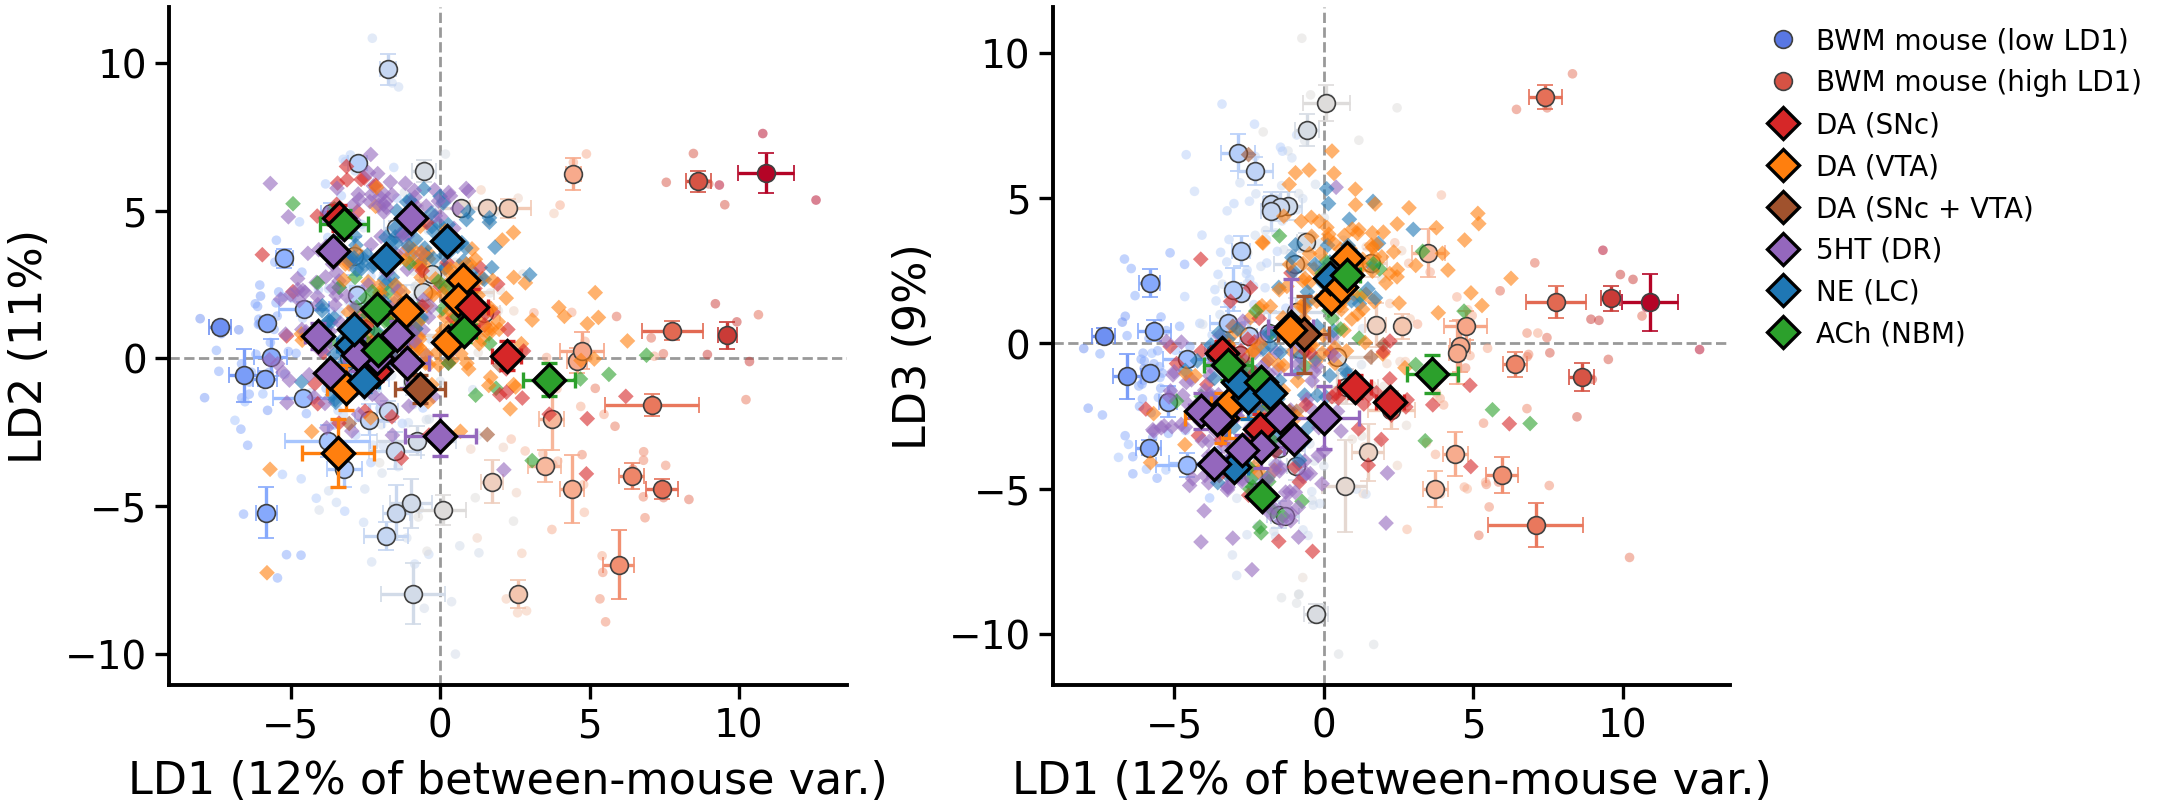

In [3]:
#%%
""" FIGURE, as fig_ld1 panel A: sessions small, mouse means (+/- SEM) large. BWM mice on the LD1 gradient
(ps.ld1_colors of the mouse-mean LD1, scale from the BWM mice only); NM mice in their neuromodulator colours,
diamonds with a black edge so they cannot be mistaken for BWM mice at the red / blue ends; DA split by target. """
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import paper_style as ps
ps.use('paper')
# by fiber target; DA split into SNc and VTA (ZFM-04022 has one fiber in each: its own category)
NM_COL = {'SNc-DA': '#d62728', 'VTA-DA': '#ff7f0e', 'SNc-DA+VTA-DA': '#a0522d', 'DR-5HT': '#9467bd',
          'LC-NE': '#1f77b4', 'NBM-ACh': '#2ca02c'}
NM_LABEL = {'SNc-DA': 'DA (SNc)', 'VTA-DA': 'DA (VTA)', 'SNc-DA+VTA-DA': 'DA (SNc + VTA)', 'DR-5HT': '5HT (DR)',
            'LC-NE': 'NE (LC)', 'NBM-ACh': 'ACh (NBM)'}
SHARE = emb.axis_share
B = A[A['group'] == 'BWM proficient']
N = A[A['group'] == 'NM'].join(META[['target']], on='mouse_name')
norm = ps.ld1_norm(B.groupby('mouse_name')['LD1'].mean().to_numpy())


def lda_panel(ax, x, y):
    g = B.groupby('mouse_name')
    mm, se = g[[x, y]].mean(), g[[x, y]].std().div(np.sqrt(g.size()), axis=0)
    col = dict(zip(mm.index, ps.LD1_CMAP(norm(g['LD1'].mean().reindex(mm.index).to_numpy()))))
    ax.scatter(B[x], B[y], c=[col[m] for m in B['mouse_name']], s=3, alpha=0.5, lw=0, zorder=1)
    for m in mm.index:
        ax.errorbar(mm.loc[m, x], mm.loc[m, y], xerr=se.loc[m, x], yerr=se.loc[m, y], fmt='o', ms=3.2,
                    color=col[m], ecolor=col[m], elinewidth=0.6, mec='0.25', mew=0.3, zorder=2)
    gn = N.groupby('mouse_name')
    mn, sn = gn[[x, y]].mean(), gn[[x, y]].std().div(np.sqrt(gn.size()), axis=0)
    ax.scatter(N[x], N[y], c=[NM_COL[t] for t in N['target']], s=4, alpha=0.6, lw=0, marker='D', zorder=3)
    for m in mn.index:
        c = NM_COL[N.loc[N['mouse_name'] == m, 'target'].iloc[0]]
        ax.errorbar(mn.loc[m, x], mn.loc[m, y], xerr=sn.loc[m, x], yerr=sn.loc[m, y], fmt='D', ms=4,
                    color=c, ecolor=c, elinewidth=0.6, mec='k', mew=0.6, zorder=4)
    for f in (ax.axvline, ax.axhline):
        f(0, color='0.6', ls='--', lw=0.5, zorder=0)
    ax.set_box_aspect(1)
    ax.set_xlabel(f'{x} ({100 * SHARE[int(x[2:]) - 1]:.0f}% of between-mouse var.)')
    ax.set_ylabel(f'{y} ({100 * SHARE[int(y[2:]) - 1]:.0f}%)')


fig, axes = plt.subplots(1, 2, figsize=(5.6, 2.9))
for ax, (x, y) in zip(axes, [('LD1', 'LD2'), ('LD1', 'LD3')]):
    lda_panel(ax, x, y)
handles = [plt.Line2D([], [], marker='o', ls='', color=ps.LD1_CMAP(0.1), mec='0.25', mew=0.3, ms=3.2, label='BWM mouse (low LD1)'),
           plt.Line2D([], [], marker='o', ls='', color=ps.LD1_CMAP(0.9), mec='0.25', mew=0.3, ms=3.2, label='BWM mouse (high LD1)')] + \
          [plt.Line2D([], [], marker='D', ls='', color=c, mec='k', mew=0.6, ms=4, label=NM_LABEL[t]) for t, c in NM_COL.items()]
axes[1].legend(handles=handles, fontsize=5, frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
FIG_DIR = pathlib.Path('figures'); FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / 'nm_in_bwm_lda.png', dpi=300, bbox_inches='tight')
fig.savefig(FIG_DIR / 'nm_in_bwm_lda.svg', bbox_inches='tight')
plt.show()

In [4]:
#%%
""" 1. WHERE THEY LAND: group centroids and spreads in BWM between-mouse SD units; centroid distance (all
LDs) against the expected distance of a random group of the same size """
tab, typical = npj.group_table(A, LAB)
print(f'mean distance of a BWM mouse from the BWM centre: {typical:.2f}')
tab.sort_values('centroid_dist').round(2)

mean distance of a BWM mouse from the BWM centre: 12.14


,n_mice,centroid_dist,chance_dist,LD1 mean,LD2 mean,LD3 mean,LD4 mean,LD5 mean,LD1 sd,LD2 sd,LD3 sd,LD4 sd,LD5 sd
group,,,,,,,,,,,,,
Pre-rec (same mice),37,4.91,1.21,-0.14,0.14,0.27,0.10,-0.04,1.02,0.73,1.03,0.85,1.01
lab: churchlandlab_ucla,5,5.63,5.24,0.38,-0.50,-0.62,0.26,0.13,0.82,0.94,1.04,0.71,1.55
lab: steinmetzlab,4,5.90,5.91,-0.01,-0.74,-0.04,-0.17,-0.33,0.81,0.30,0.79,0.16,1.17
lab: wittenlab,3,6.02,6.89,0.30,0.21,-0.50,-0.12,0.34,0.72,0.15,0.91,0.79,0.92
lab: danlab,7,6.05,4.34,-0.31,0.21,0.75,1.06,0.51,0.44,1.57,0.54,0.98,1.14
lab: mrsicflogellab,4,6.18,5.91,0.16,0.75,-0.78,0.22,-0.20,0.62,0.74,0.66,0.66,0.83
lab: hausserlab,6,6.27,4.74,-0.53,0.03,-0.39,1.10,0.20,1.14,0.82,0.80,0.73,0.72
lab: churchlandlab,7,6.38,4.34,-0.83,-0.25,-0.32,-0.87,0.20,0.85,0.47,0.62,0.60,0.55
lab: mainenlab,7,6.81,4.34,-0.34,-0.51,1.02,-0.93,0.21,0.26,1.15,0.84,0.64,0.72


In [5]:
#%%
""" is the NM offset the Pre-rec offset (same mice, same rig, 30 Hz camera) or the lab (mainenlab among BWM)? """
npj.offset_decomposition(A, LAB).round(3)

|NM offset|            9.251
|Pre-rec offset|       4.822
|mainenlab offset|     6.811
cos(NM, Pre-rec)       0.688
cos(NM, mainenlab)    -0.002
cos chance SD          0.132
NM ~ a Pre-rec: a      1.320
NM ~ b mainenlab: b   -0.002
R2 of NM offset        0.473
dtype: float64

In [6]:
#%%
""" 2. DO NM MICE CLUSTER BY MOUSE IN BWM AXES? leave-one-session-out nearest mouse centroid.
And the 30 Hz check: each Pre-rec session assigned to the nearest of the 58 BWM proficient mice. """
display(npj.nm_identification(A).round(3).to_frame('NM mouse ID').T)
npj.prerec_identification(A).round(3).to_frame('Pre-rec -> its proficient mouse').T

,LD1-3,LD1-10,LD1-20,LD1-57,shuffled (all LDs),chance
NM mouse ID,0.313,0.641,0.764,0.827,0.025,0.033


,LD1-3,LD1-10,LD1-57,chance,sessions
Pre-rec -> its proficient mouse,0.226,0.484,0.527,0.017,93.0


In [7]:
#%%
""" 3. IS IT THE SAME LD1? the projected LDs against the NM session measures (same definitions as BWM),
and the profile test against the BWM LD1's correlates (null: NM mouse labels permuted) """
Zn = A[A['group'] == 'NM'].drop(columns='group')
M = n.session_measures(Zn.index)
corr = n.mouse_corr(Zn, M, cols=('LD1', 'LD2', 'LD3'), n_perm=5000)
BWM = n.bwm_ld1_profile()
display(n.profile_test(Zn, M, BWM, cols=('LD1', 'LD2', 'LD3')).round(3))
P = corr.pivot(index='metric', columns='ld', values='r').join(
    corr.pivot(index='metric', columns='ld', values='p_perm'), rsuffix=' p').join(BWM, how='inner')
P[['LD1', 'LD1 p', 'BWM LD1', 'LD2', 'LD3']].sort_values('BWM LD1').round(2)

,ld,profile_r,null_95,p,n_measures,n_mice
0,LD1,0.865,0.735,0.002,31,30
1,LD2,0.528,0.739,0.271,31,30
2,LD3,0.785,0.738,0.024,31,30


,LD1,LD1 p,BWM LD1,LD2,LD3
wheel_gate,-0.56,0.00,-0.64,-0.34,-0.53
paw_gate,-0.45,0.01,-0.61,-0.10,-0.41
log_reaction,-0.61,0.00,-0.55,-0.49,-0.49
wheel_speed_Pre-quiescence,-0.27,0.14,-0.42,-0.07,-0.43
wheel_mean_speed_moving,-0.28,0.14,-0.39,0.17,-0.35
dur_Quiescence,-0.15,0.44,-0.36,-0.43,-0.36
switches,-0.18,0.34,-0.36,0.04,-0.21
short_bouts,-0.18,0.35,-0.34,0.02,-0.33
l_paw_mean_speed_moving,-0.30,0.11,-0.32,0.16,-0.37
entropy,-0.24,0.19,-0.29,-0.04,-0.22


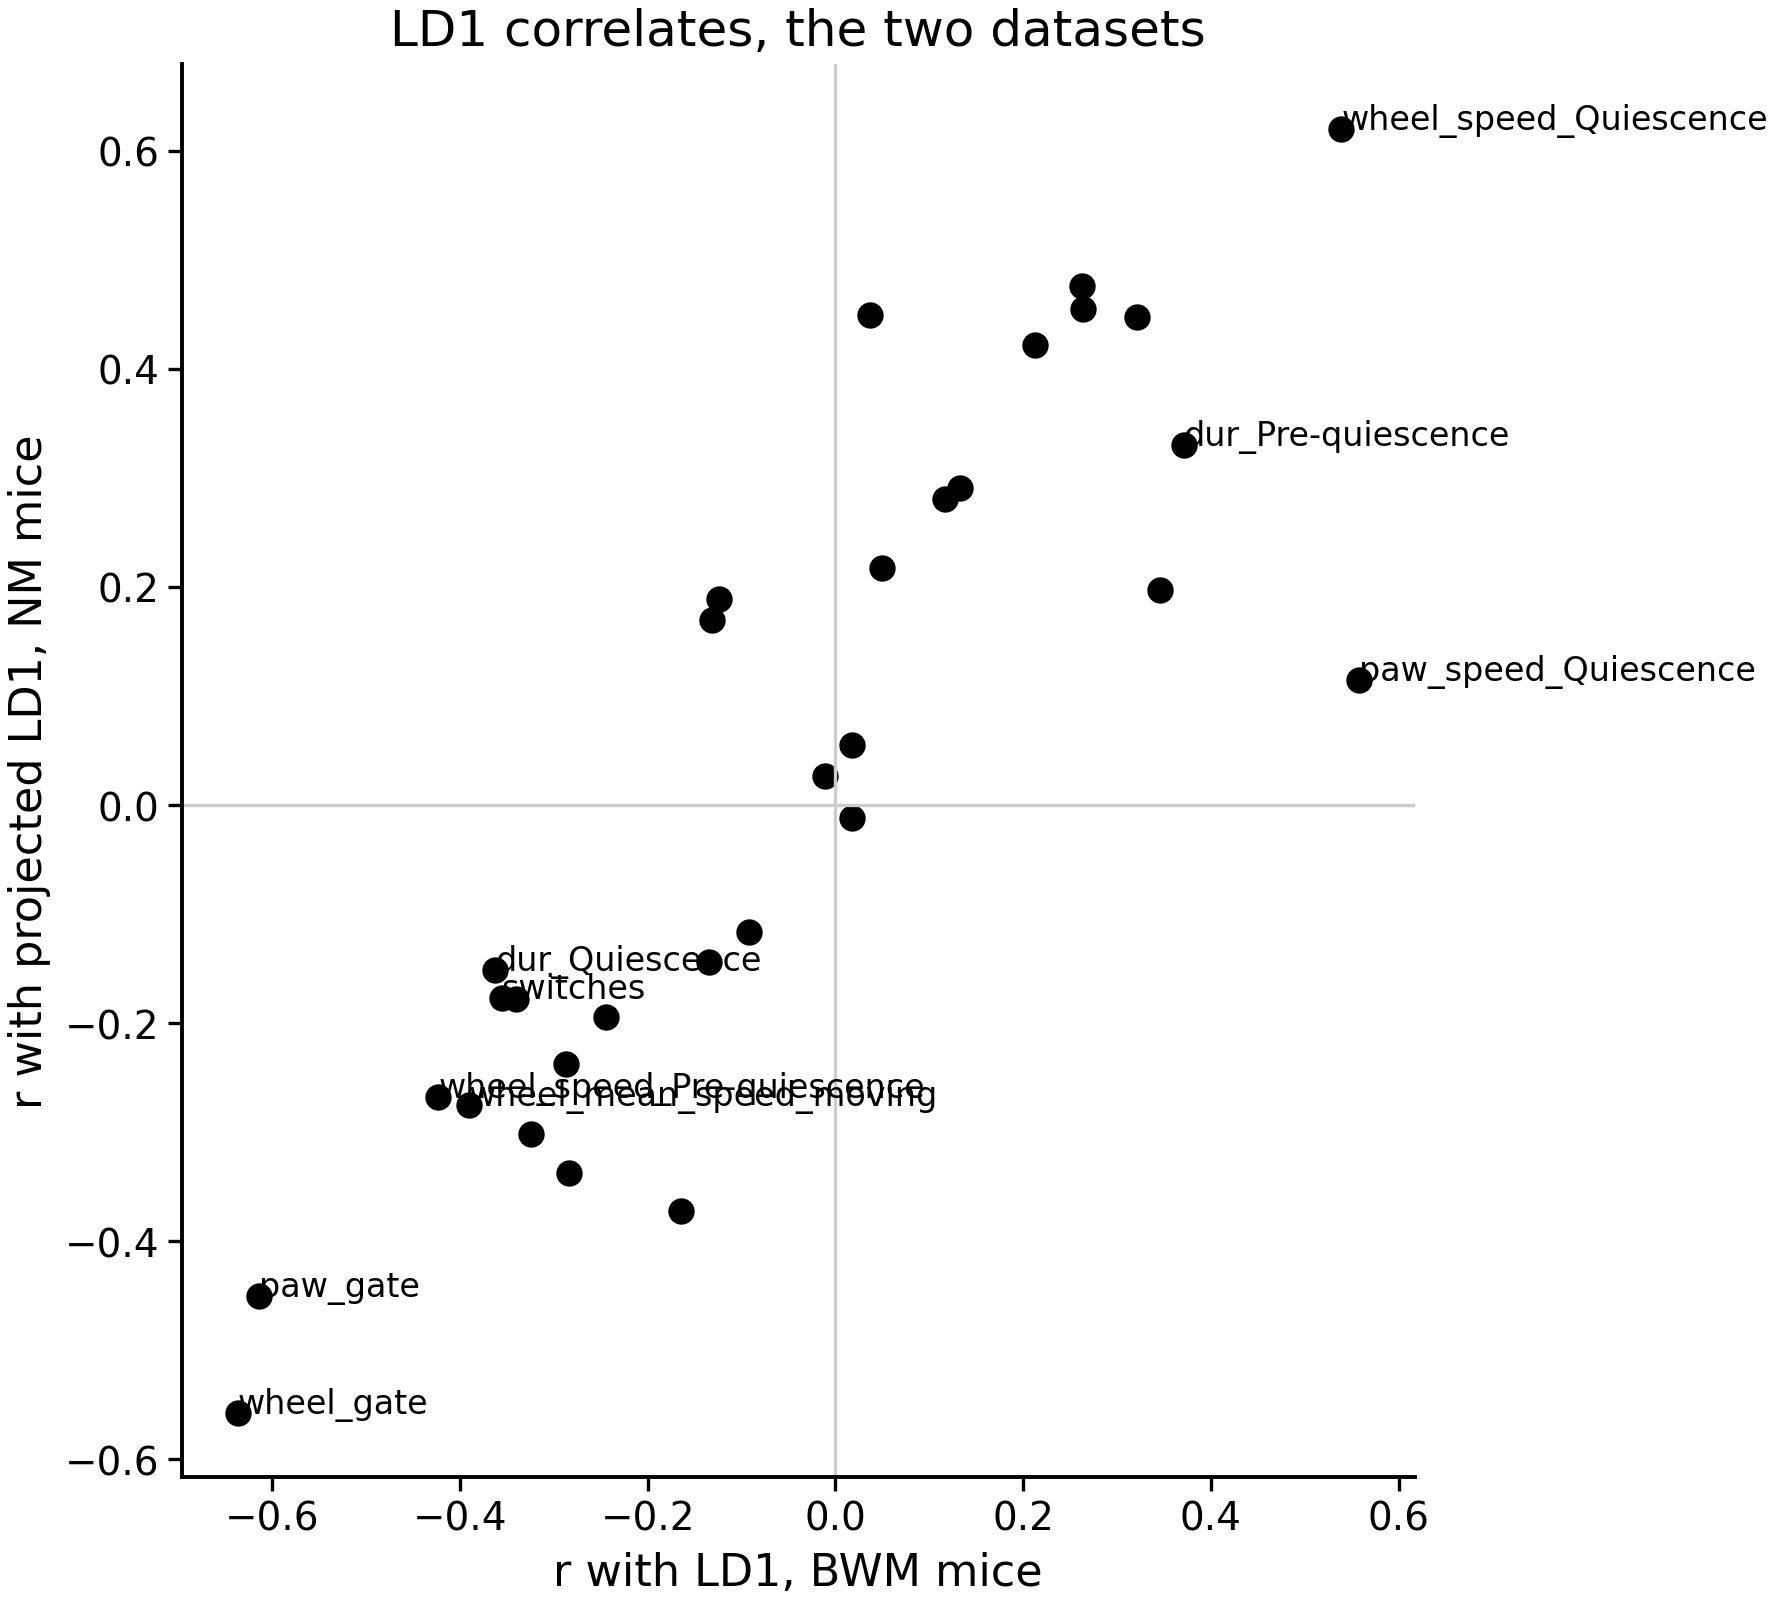

In [8]:
#%%
fig, a = plt.subplots(figsize=(4.6, 4.2))
Q = P.drop(index='log_reaction')
a.axhline(0, color='.8', lw=.6); a.axvline(0, color='.8', lw=.6)
a.scatter(Q['BWM LD1'], Q['LD1'], s=14, color='k')
for m, r in Q.iterrows():
    if abs(r['BWM LD1']) > .35 or abs(r['LD1']) > .5:
        a.annotate(m, (r['BWM LD1'], r['LD1']), fontsize=6)
a.set_xlabel('r with LD1, BWM mice'); a.set_ylabel('r with projected LD1, NM mice')
a.set_title('LD1 correlates, the two datasets', fontsize=9)
plt.tight_layout(); plt.show()

In [9]:
#%%
""" the projected axes vs NM's own LDA (2_nm_lda), mouse means """
import proficient_1cam as pc
Xo, mo = n.design('ephys', verbose=False)
eo, so = pc.embed(Xo, mo)
so = so.drop(columns='lab')
n.orient_by(so, eo, n.session_measures(Xo.index))
mm = Zn.groupby('mouse_name')[['LD1', 'LD2', 'LD3']].mean().join(
    so.groupby('mouse_name')[['LD1', 'LD2', 'LD3']].mean(), rsuffix=' (NM own)')
mm.corr().loc[['LD1', 'LD2', 'LD3'], ['LD1 (NM own)', 'LD2 (NM own)', 'LD3 (NM own)']].round(2)

,LD1 (NM own),LD2 (NM own),LD3 (NM own)
LD1,0.59,0.15,-0.36
LD2,0.28,-0.38,0.56
LD3,0.66,0.09,-0.34


## Reading (both protocols, 30 NM mice; the ephys-only numbers in brackets)

- **The protocols can be pooled.** For the 16 mice with both, ephys and biased mouse means agree across mice
  (r 0.70–0.82 on LD1–LD5), shift ≤ 0.2 BWM SD, and a biased session finds its mouse's ephys centroid 60 % of
  the time (chance 6 %), about what Pre-rec does across camera settings.
- **The frame transfers across camera settings.** Pre-rec sessions of the BWM mice (same rig, 30 Hz) land near their
  own proficient positions (r ≈ 0.73–0.83 per LD) and pick their own mouse out of 58 at 0.53 (chance 0.017).
- **NM mice are individually separable in BWM axes**: 0.83 leave-one-session-out among 30 mice, chance 0.03
  [0.96 among 12], axes never fitted on NM.
- **Where they land**: inside the BWM range on LD1 (group mean −0.3 BWM SD [−0.1]), narrower spread (0.4–0.6×,
  one lab). As a group displaced (centroid 9.3 LD units from the BWM centre [9.7]; chance ≈ 1.6), along the
  **Pre-rec offset** (cosine 0.69 vs Pre-rec − proficient, same mice and rig at 30 Hz; chance SD 0.13; 47 % of
  it) and **not** along mainenlab's BWM offset (cosine 0): what NM shares with Pre-rec is 30 Hz acquisition
  (and the 100 ms lick HMM), not the lab; the rest of the NM offset is its own rigs / setup.
- **The BWM LD1 is the same axis within NM**: correlate profile r = 0.87, p = 0.002 [0.80, p = 0.012]; faster
  RT (−0.61), weak pre-quiescence / quiescence wheel gate (−0.56), more wheel movement in quiescence (+0.62),
  each p ≤ 0.002. The engagement-switching link is weaker here (−0.18 [−0.42]).
- Neuromodulator type does not organise LD1–LD3 (Kruskal p ≥ 0.08, 5–11 mice per type).

Next: the same without the whisk / lick features (dataset-specific HMMs), then NM mice's LD1 position against
their neuromodulator measures.